In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
domainM='GRq'; nx=ny=10
domainM='GRq'
ds_TTZ_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
    'TTZ_day_MARv3.14_ER5_spin2_GRq_1980-2024.nc')['TTZ'].sel(ZTQLEV=2)
ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
ds_TTZ=ds_TTZ[:,ny:-ny,nx:-nx]

In [3]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [4]:
#ds_TF=ds_SF+ds_RF

In [5]:

def daily_lapse_rate(ds_TTZ, dsSH):
    lapse_rates = []
    for t in ds_TTZ.time:
        T = ds_TTZ.sel(time=t).values.flatten()
        Z = dsSH.values.flatten()
        mask = np.isfinite(T) & np.isfinite(Z)

        slope, _, _, _, _ = stats.linregress(Z[mask], T[mask])
        lapse_rates.append(slope * 1000)  # °C/km

    return xr.DataArray(
        lapse_rates,
        coords=[ds_TTZ.time],
        dims=["time"],
        name="lapse_rate"
    )


In [6]:
lr_daily = daily_lapse_rate(ds_TTZ, dsSH)

In [7]:
lr_daily 

<xarray.DataArray 'lapse_rate' (time: 16437)>
array([-6.00177744, -6.44782856, -6.54003115, ..., -6.22571886,
       -5.9773202 , -5.4056666 ])
Coordinates:
  * time     (time) datetime64[ns] 1980-01-01T12:00:00 ... 2024-12-31T12:00:00

In [8]:
##GLACIOCLIM
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_meteo/'
#
##
#Pyramid
#5035 m a.s.l (off-glacier)	2019 à 2024 X
#
#Mera La ML
#5350 m a.s.l (off-glacier)	2013 à 2024 X
#Mera 5770 M5
#5770 m a.s.l (on-glacier)	2017 à 2024
#Mera Naulek MN
#5350 m a.s.l (on-glacier)	2012 à 2024 X
#Mera Summit MS
#6350 m a.s.l (on-glacier)	2013 à 2016 X


In [9]:
#West Changri Nup
#5360 m a.s.l (on-glacier)	2010 à 2012
#2012 à 2014
#2014 à 2024
#North Changri Nup
#5470 m a.s.l (on-glacier)	2014 à 2017

In [10]:
fileName='AWS_Pyramid_2019_2024.xlsx'
lat_PYG= 27.95892;lon_PYG=86.812987;elev_PYG=5035 

xl_file_PYG= pd.ExcelFile(sourceData+fileName)
dfs_PYG = {sheet_name: xl_file_PYG.parse(sheet_name) 
          for sheet_name in xl_file_PYG.sheet_names}
File_PYG=dfs_PYG['Pyramid_2019_24']
UnitVars_PYG=['(°C)','(%)','Dist sensor-surf','Dist sensor-surf','(m/s)','AWS (°)','(m/s)','(hPa)','(W/m2)',
              '(W/m2)','(W/m2)','(W/m2)','(mm)','(°C)','(%)','(m/s)', 'Geonor (°)','(m/s)','(mm)','(mm)','(mm)']
NameVars_PYG=['Time','Tair_AWS','RH_AWS','Abl_Acc','Abl_Acc','u_AWS','Direction','u_max_AWS','Patm','SWin','SWout','LWin_cor','LWout_cor','Geonor','Tair_Geonor','RH_Geonor','u_Geonor',
              'Direction','u_max_Geonor','Geonor','Geonor','Geonor']

dfile_PYG = pd.DataFrame(data=File_PYG.loc[5:])
df_PYG=pd.DataFrame(dfile_PYG.values, columns=NameVars_PYG)
#print(df_PYG.head())

time_clean = pd.to_datetime(df_PYG["Time"], errors="coerce").values
NameVar = "tair"

ds_PYG_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_PYG["Tair_AWS"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_PYG_raw = ds_PYG_tair.resample(time='1D').mean()
#ds_daily = ds_PYG_tair.resample(time='1D').max()
#ds_daily = ds_PYG_tair.resample(time='1D').min()
#ds_daily = ds_PYG_tair.resample(time='1D').sum()
tt_daily_PYG=tt_daily_PYG_raw.tair

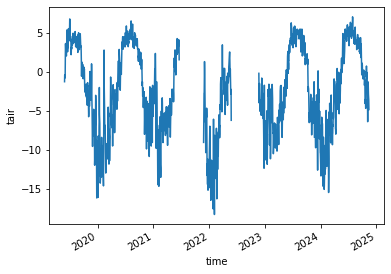

In [11]:
tt_daily_PYG.plot()

In [12]:
##MeraLafinal2013_24.xlsx
###
#AWS-Mera La: Since November 2013 (AWS inserted on firm rocks – off-glacier)
#Location in WGS84, Lat: 27.735°N; Long: 86.900°E; Elevation: 5352.008 m 
#or UTM Zone 45; Easting: 490137.007 m; Northing: 3067850.613 m on 22/11/2020
###

fileName='MeraLafinal2013_24.xlsx'

xl_file_MeraLa = pd.ExcelFile(sourceData+fileName)

dfs_MeraLa = {sheet_name: xl_file_MeraLa.parse(sheet_name) 
          for sheet_name in xl_file_MeraLa.sheet_names}
File_MeraLa=dfs_MeraLa['MeraLa2013_23']

NameVars_MeraLa=['Time','Tair','RH','u','Direction','SWin','SWout','LWin','LWout','Patm']
UnitVars_MeraLa=['data/hour','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraLa = pd.DataFrame(data=File_MeraLa.loc[4:])
df_MeraLa=pd.DataFrame(dfile_MeraLa.values, columns=NameVars_MeraLa)

df_MeraLa.head()
### Opening one column + converting into an array
Tair_ar=[float(i) for i in df_MeraLa.Tair.values]

NameVar="Tair"; Var_ar=Tair_ar

start, end = df_MeraLa.Time.values[0], df_MeraLa.Time.values[-1]
time = pd.date_range(start, end, freq='30min')
ds_MeraLa = xr.Dataset({NameVar: ("time",np.asarray(Var_ar)), "time": time})

tt_daily_ML = ds_MeraLa.Tair.resample(time='D').mean()


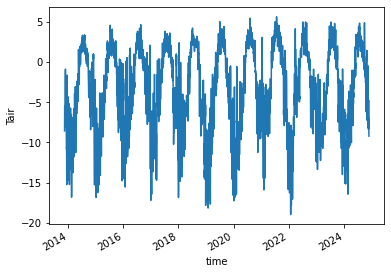

In [13]:
tt_daily_ML.plot()

In [14]:
##Mera Naulek
def NewTime(df,NameVar, Var_ar, freq):
    start = df.Time.values[0]
    time = pd.date_range(start=start, periods=len(Var_ar), freq=freq)
    ds = xr.DataArray(Var_ar, dims='time', coords={'time': time}, name=NameVar)
    return ds

fileName='Naulekfinal2012_24.xlsx'

xl_file_MeraNaulek = pd.ExcelFile(sourceData+fileName)

dfs_MeraNaulek = {sheet_name: xl_file_MeraNaulek.parse(sheet_name) 
          for sheet_name in xl_file_MeraNaulek.sheet_names}

File_MeraNaulek=dfs_MeraNaulek['Naulekfinal2012_24']

NameVars_MeraNaulek=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','Abl/acc dist sensor surf','tilt metter XAXIS','tilt meter YAXIX']
UnitVars_MeraNaulek=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','m','degrees','degrees']


##Define new DataFrame and changing name of columns
dfile_MeraNaulek = pd.DataFrame(data=File_MeraNaulek.loc[4:])
df_MeraNaulek=pd.DataFrame(dfile_MeraNaulek.values, columns=NameVars_MeraNaulek)
### Opening one column + converting into an array
Tairlow_ar=[float(i) for i in df_MeraNaulek.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar=[float(i) for i in df_MeraNaulek.Tairhigh.values] 
    
ds_Tlow_MeraNaulek=NewTime(df_MeraNaulek,'Tairlow',Tairlow_ar,'30min')
ds_Thigh_MeraNaulek=NewTime(df_MeraNaulek,'Tairhigh',Tairhigh_ar,'30min')
tlow_daily_mean_MeraNaulek  = ds_Tlow_MeraNaulek.resample(time='D').mean()
thigh_daily_mean_MeraNaulek  = ds_Thigh_MeraNaulek.resample(time='D').mean()



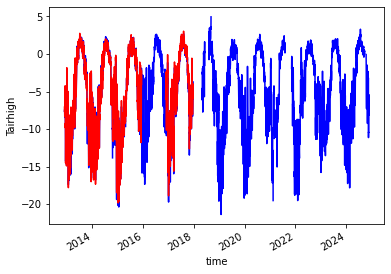

In [15]:
tlow_daily_mean_MeraNaulek.plot(color='blue')
thigh_daily_mean_MeraNaulek.plot(color='red')

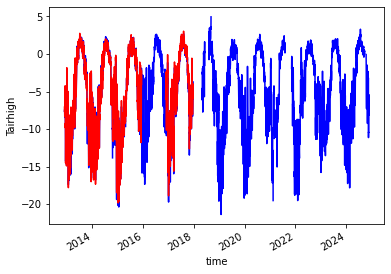

In [16]:
tlow_aligned, thigh_aligned = xr.align(
    tlow_daily_mean_MeraNaulek,
    thigh_daily_mean_MeraNaulek,
    join="inner"
)
tlow_aligned.plot(color='blue')
thigh_aligned.plot(color='red')

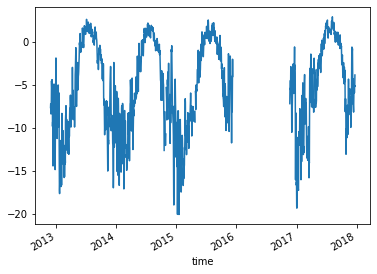

In [17]:
tmean = (tlow_aligned + thigh_aligned) / 2
tmean.plot()

In [18]:
tt_daily_MN=tmean
tmean.time[-1]

<xarray.DataArray 'time' ()>
array('2024-11-26T00:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2024-11-26

In [19]:
## Mera Summit

fileName='MeraSummit_2013-16.xlsx'

xl_file_MeraSummit = pd.ExcelFile(sourceData+fileName)

df_MeraSummit= {sheet_name: xl_file_MeraSummit.parse(sheet_name)     
       for sheet_name in xl_file_MeraSummit.sheet_names}
Data_MeraSummit=df_MeraSummit['MeraSummit2013_16']                  
NameVars_MeraSummit=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','T1snow','T2snow','T3snow','T4snow','T5snow','T6snow','Abl/acc dist sensor surf','Quality number SR50','Patm']
UnitVars_MeraSummit=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','C','C','C','C','C','C','m','','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraSummit= pd.DataFrame(data=Data_MeraSummit.loc[4:]) 
df_MeraSummit=pd.DataFrame(dfile_MeraSummit.values, columns=NameVars_MeraSummit) 

### Opening one column + converting into an array
Tairlow_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairhigh.values] 


ds_Tlow_MeraSummit = NewTime(df_MeraSummit,'Tairlow', Tairlow_ar_MeraSummit, '30min')
ds_Thigh_MeraSummit = NewTime(df_MeraSummit,'Tairhigh', Tairhigh_ar_MeraSummit, '30min')
ds_Tmean_MeraSummit = (ds_Tlow_MeraSummit + ds_Thigh_MeraSummit) / 2
ds_Tmean_MeraSummit.name = 'Tairmean'  # optional, rename variable

tlow_daily_mean_MeraSummit  = ds_Tlow_MeraSummit.resample(time='D').mean()
thigh_daily_mean_MeraSummit  = ds_Thigh_MeraSummit.resample(time='D').mean()
tmean_daily_mean_MeraSummit  = ds_Tmean_MeraSummit.resample(time='D').mean()

tt_daily_MS=tmean_daily_mean_MeraSummit

In [20]:
fileName='Changri5360final2014_24.xlsx'

xl_file_CHA3= pd.ExcelFile(sourceData+fileName)
dfs_CHA3 = {sheet_name: xl_file_CHA3.parse(sheet_name) 
          for sheet_name in xl_file_CHA3.sheet_names}

File_CHA3=dfs_CHA3['Changri_5360_2014_23']

NameVars_CHA3 = ["Date","SWin","SWout","LWin","LWout","Tair","RH","Height/surf","u high","Direction",
                    "Flux -21cm","T1 -1cm","T2 -16cm","T3 -21cm","u low","Direction"]

dfile_CHA3= pd.DataFrame(data=File_CHA3.loc[12:])
df_CHA3=pd.DataFrame(dfile_CHA3.values, columns=NameVars_CHA3)
print(df_CHA3.head())
time_clean = pd.to_datetime(df_CHA3["Date"], errors="coerce").values
NameVar = "Tair"

ds_CHA3_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_CHA3["Tair"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_CHA3_raw = ds_CHA3_tair.resample(time='1D').mean()
tt_daily_CHA3=tt_daily_CHA3_raw.Tair

                 Date    SWin   SWout    LWin   LWout    Tair      RH  \
0 2014-11-30 13:00:00  805.12   156.7  29.026  215.88  3.2685  7.4238   
1 2014-11-30 13:30:00   759.9  147.56  195.46  379.23   3.251  7.1217   
2 2014-11-30 14:00:00   692.5  133.82  194.69  376.27  3.2897  7.5707   
3 2014-11-30 14:30:00  607.17  117.99  194.24  375.13  3.3542  7.3504   
4 2014-11-30 15:00:00  507.74  98.694  192.92  367.47  2.9335  7.2352   

  Height/surf u high Direction Flux -21cm T1 -1cm T2 -16cm T3 -21cm  u low  \
0       0.884  4.541     174.5     16.179  7.5551      NaN      NaN  4.022   
1        0.88  5.179     263.3     17.151  12.908  -3.1084  -4.2914  4.604   
2       0.875  4.239     191.5     17.638   10.97  -2.6814  -3.9885  3.804   
3       0.881   3.26     210.9     17.519  10.885  -2.3063  -3.7073  3.002   
4       0.878  3.778     175.8     16.894   9.797  -2.0093  -3.4627  3.478   

  Direction  
0     195.2  
1     293.5  
2     192.2  
3       263  
4     215.8  


In [21]:
#Mera5770 2017-2024
#	Easting (m)	Northing (m)	Elevation (m)
#	488409,424	3066148,049	5769,233

In [22]:
fileName='Mera5770final2017_24.xlsx'
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_meteo/'
xl_file_M57= pd.ExcelFile(sourceData+fileName)
dfs_M57 = {sheet_name: xl_file_M57.parse(sheet_name) 
          for sheet_name in xl_file_M57.sheet_names}

File_M57=dfs_M57['Mera_5770_2017_24']

NameVars_M57 = ["Date","Tair","RH","u","Direction","SWin","SWout","LWin_cor",
                 "LWout_cor","Abl_Acc","Patm"]
File_M57

,"AWS Mera Glacier, uncovered part",Unnamed: 1,Easting (m),Northing (m),Elevation (m),on 10 nov. 2017,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,Years 2017-22,NaN,488409.424,3066148.049,5769.233,UTM North Zone 45. WGS84,NaN,NaN,NaN,NaN,NaN
1,Date / Hour,Tair,RH,u,Direction,SWin,SWout,LWin cor,LWout cor,Abl/Acc,Patm
2,NaN,(°C),(%),(m/s),(°),(W/m2),(W/m2),(W/m2),(W/m2),Dist sensor-surf,(hPa)
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(m),NaN
4,2017-11-10 12:00:00,-9.49,20.16,NaN,NaN,820.9,546.48,143.74,316.3,NaN,527.1
...,...,...,...,...,...,...,...,...,...,...,...
113819,2024-05-08 15:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113820,2024-05-08 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113821,2024-05-08 16:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113822,2024-05-08 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
dfile_M57= pd.DataFrame(data=File_M57.loc[4:])
print(dfile_M57.head())

  AWS Mera Glacier, uncovered part Unnamed: 1 Easting (m) Northing (m)  \
4              2017-11-10 12:00:00      -9.49       20.16          NaN   
5              2017-11-10 12:30:00      -8.01       21.59        0.593   
6              2017-11-10 13:00:00      -9.25       26.82        0.135   
7              2017-11-10 13:30:00     -10.05       32.56        1.594   
8              2017-11-10 14:00:00       -9.9       37.52        1.778   

  Elevation (m) on 10 nov. 2017 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9  \
4           NaN           820.9     546.48     143.74      316.3        NaN   
5           NaN          843.72     481.11     237.88     329.43      1.299   
6           NaN           831.1     528.49     154.84     284.99        NaN   
7           NaN          801.07     518.36     152.78     281.32        NaN   
8           NaN          744.81     483.28      154.3     280.49        NaN   

  Unnamed: 10  
4       527.1  
5       526.6  
6       526.5  
7       526.3  


In [24]:
df_M57=pd.DataFrame(dfile_M57.values, columns=NameVars_M57)
print(df_M57.head())
time_clean = pd.to_datetime(df_M57["Date"], errors="coerce").values
NameVar = "Tair"

ds_M57_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_M57["Tair"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_M57_raw = ds_M57_tair.resample(time='1D').mean()
tt_daily_M57=tt_daily_M57_raw.Tair

                 Date    Tair     RH      u Direction    SWin   SWout  \
0 2017-11-10 12:00:00   -9.49  20.16    NaN       NaN   820.9  546.48   
1 2017-11-10 12:30:00   -8.01  21.59  0.593       NaN  843.72  481.11   
2 2017-11-10 13:00:00   -9.25  26.82  0.135       NaN   831.1  528.49   
3 2017-11-10 13:30:00  -10.05  32.56  1.594       NaN  801.07  518.36   
4 2017-11-10 14:00:00    -9.9  37.52  1.778       NaN  744.81  483.28   

  LWin_cor LWout_cor Abl_Acc   Patm  
0   143.74     316.3     NaN  527.1  
1   237.88    329.43   1.299  526.6  
2   154.84    284.99     NaN  526.5  
3   152.78    281.32     NaN  526.3  
4    154.3    280.49     NaN  526.9  


In [25]:
tt_daily_M57

<xarray.DataArray 'Tair' (time: 2372)>
array([-11.31791667,  -9.573     ,  -8.100125  , ...,          nan,
                nan,          nan])
Coordinates:
  * time     (time) datetime64[ns] 2017-11-10 2017-11-11 ... 2024-05-08

In [26]:
idatePYG = str(tt_daily_PYG.time[0].values)[:10]
fdatePYG = str(tt_daily_PYG.time[-1].values)[:10]
              
idateML = str(tt_daily_ML.time[0].values)[:10]
fdateML = str(tt_daily_ML.time[-1].values)[:10]

idateMS = str(tt_daily_MS.time[0].values)[:10]
fdateMS = str(tt_daily_MS.time[-1].values)[:10]

idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]
fdateMN = str(tlow_daily_mean_MeraNaulek.time[-1].values)[:10]

#idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]

idateCHA3=str(tt_daily_CHA3.time[0].values)[:10]
fdateCHA3=str(tt_daily_CHA3.time[-1].values)[:10]

idateM57=str(tt_daily_M57.time[0].values)[:10]
fdateM57=str(tt_daily_M57.time[-1].values)[:10]


In [27]:
###
## PYRAMID Salerno
### 

In [28]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

#

                       AT   RR     AP    RH    WS  WD
TIMESTAMP                                            
1994-01-01 02:00:00 -11.9  0.0  551.4  25.0  0.00 NaN
1994-01-01 04:00:00 -13.2  0.0  551.0  23.0  0.00 NaN
1994-01-01 06:00:00 -10.5  0.0  551.1  10.0  0.26 NaN
1994-01-01 08:00:00 -10.9  0.0  551.9  17.0  0.00 NaN
1994-01-01 10:00:00  -7.1  0.0  553.1  17.0  5.58 NaN


In [29]:
print(df_AWSSC.head())

                     AT  AP  RH  WS  WD
TIMESTAMP                              
2008-05-01 00:00:00 NaN NaN NaN NaN NaN
2008-05-01 01:00:00 NaN NaN NaN NaN NaN
2008-05-01 02:00:00 NaN NaN NaN NaN NaN
2008-05-01 03:00:00 NaN NaN NaN NaN NaN
2008-05-01 04:00:00 NaN NaN NaN NaN NaN


In [30]:
 #Daily total precipitation (sum of hourly rates)
tt_AWS0_daily = df_AWS0['AT'].resample('D').mean()
tt_AWS1_daily = df_AWS1['AT'].resample('D').mean()
tt_AWS2_daily = df_AWS2['AT'].resample('D').mean()
tt_AWS3_daily = df_AWS3['AT'].resample('D').mean()
tt_AWS4_daily = df_AWS4['AT'].resample('D').mean()
tt_AWS5_daily = df_AWS5['AT'].resample('D').mean()
tt_AWSSC_daily = df_AWSSC['AT'].resample('D').mean()
tt_CNG_daily = df_CNG['AT'].resample('D').mean()


In [31]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    #print(df.head())
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df[df < -100] = np.nan
    
tt_bc_daily = df_bc['T_HMP'].resample('D').mean()
tt_c2_daily = df_c2['T_HMP'].resample('D').mean()
tt_phort_daily = df_phort['T_HMP'].resample('D').mean()
tt_bish_daily = df_bish['T_HMP'].resample('D').mean()
tt_sc_daily = df_sc['T_HMP'].resample('D').mean()


                     T_HMP      RH   PRESS  PRECIP
TIMESTAMP                                         
2019-10-17 13:00:00 -4.078  99.578  536.71     0.0
2019-10-17 14:00:00 -4.282  92.273  537.15     0.0
2019-10-17 15:00:00 -3.584  86.358  537.28     0.0
2019-10-17 16:00:00 -3.458  88.629  537.25     0.0
2019-10-17 17:00:00 -3.966  74.045  537.22     0.0


In [32]:
###Coordinates

In [33]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CHA3, lat_CHA3, elev_CHA3 = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 6351  # estimated same as MN, if not otherwise specified

# MC (Mera Central; high camp 5770)
eastingM57, northingM57 = 488409.424, 3066148.049
lon_M57, lat_M57 = transformer.transform(eastingM57, northingM57)
elev_M57 = 5769.233

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    #{"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "M57", "Name": "Mera Camp 5770", "Lat": lat_M57, "Lon": lon_M57, "Elev_m": elev_M57, "Timestep": "1h"},
    {"ID": "PYG", "Name": "Pyramid-AWS", "Lat": lat_PYG, "Lon": lon_PYG, "Elev_m": elev_PYG, "Timestep": "1h"},
    {"ID": "CHA3", "Name": "CHA3", "Lat": lat_CHA3, "Lon": lon_CHA3, "Elev_m": elev_CHA3, "Timestep": "1h"},
]


# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
      MN        Mera Naulek  27.717723    86.897390     5360.000        1h     
      ML            Mera La  27.735000    86.900000     5352.008        1h     
      KH              Khare  27.744247    86.877614     4888.000        1h     
      PH           Pheriche  27.895049    86.819729     4260.000        1h     
      PY            Pyramid  27.957822    86.812969     5035.000        1h     
      MS        Mera Summir  27.706566    86.873753     6351.000        1h     
     M57     Mera Camp 5770  27.719608    86.882420     5769.233        1h     
     PYG        Pyramid-AWS  27.958920    86.812987     5035.000        1h     
    CHA3               CHA3  27.983363    86.779484     5360.000        1h     


In [34]:
# Station coordinates and elevations
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Metadata list using the variable names
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": lat_AWSSC, "Lon": lon_AWSSC, "Elev_m": elev_AWSSC, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": lat_CNG, "Lon": lon_CNG, "Elev_m": elev_CNG, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": lat_AWS0, "Lon": lon_AWS0, "Elev_m": elev_AWS0, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": lat_AWS1, "Lon": lon_AWS1, "Elev_m": elev_AWS1, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": lat_AWS2, "Lon": lon_AWS2, "Elev_m": elev_AWS2, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": lat_AWS3, "Lon": lon_AWS3, "Elev_m": elev_AWS3, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": lat_AWS4, "Lon": lon_AWS4, "Elev_m": elev_AWS4, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": lat_AWS5, "Lon": lon_AWS5, "Elev_m": elev_AWS5, "Timestep": "1h"},
    #{"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": lat_Pyr, "Lon": lon_Pyr, "Elev_m": elev_Pyr, "Timestep": "1month"},
]
# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID          Name    Lat    Lon  Elev_m Timestep
0    AWSSC     South Col  27.98  86.76    7986       1h
1  CNG_SNP   Changri Nup  27.96  86.93    5700       1h
2     AWS0       Pyramid  27.96  86.81    5035       1h
3     AWS1       Pyramid  27.96  86.81    5035       1h
4     AWS2      Pheriche  27.90  86.82    4260       1h
5     AWS3         Lukla  27.70  86.72    2660       1h
6     AWS4  Kala Patthar  27.99  86.83    5600       1h
7     AWS5        Namche  27.80  86.71    3570       1h


In [35]:
# NatGeo Everest AWS coordinates
#Phortse Base Camp Camp II South Col Balcony  Table1 Matthews
#Latitude (°N) 27.8456 27.9952 27.9810 27.9719 27.9826
#lat_phort,lat_bc,lat_c2,lat_sc,lat_bish=27.8456, 27.9952, 27.9810, 27.9719, 27.9826
#Longitude (°E) 86.7472 86.8406 86.9023 86.9295 86.9292
#lon_phort,lon_bc,lon_c2,lon_sc,lon_bish=86.7472, 86.8406, 86.9023 ,86.9295 ,86.9292
#Elevation (m MSL) 3,810 5,315 6,464 7,945 8,430
#elev_phort,elev_bc,elev_c2,elev_sc,elev_bish=3810, 5315 ,6464 ,7945, 8430
# BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc, lon_bc, elev_bc = 27.9952, 86.8406, 5315

# CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2, lon_c2, elev_c2 = 27.9810, 86.9023, 6464 

# PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort, lon_phort, elev_phort = 27.8456, 86.7472, 3810 

# BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish, lon_bish, elev_bish = 27.9735, 86.9308, 8810 

# MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc, lon_sc, elev_sc = 27.9719, 86.9295, 7945


# Define metadata for Everest AWS network using variables
stations_info_everest = [
    {"ID": "bc", "Name": "Base Camp AWS", "Lat": lat_bc, "Lon": lon_bc, "Elev_m": elev_bc},
    {"ID": "c2", "Name": "Camp II AWS", "Lat": lat_c2, "Lon": lon_c2, "Elev_m": elev_c2},
    {"ID": "phort", "Name": "Phortse AWS", "Lat": lat_phort, "Lon": lon_phort, "Elev_m": elev_phort},
    {"ID": "bish", "Name": "Bishop Rock AWS", "Lat": lat_bish, "Lon": lon_bish, "Elev_m": elev_bish},
    {"ID": "sc", "Name": "Mt. Everest South Col AWS", "Lat": lat_sc, "Lon": lon_sc, "Elev_m": elev_sc},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)


      ID                       Name      Lat      Lon  Elev_m
0     bc              Base Camp AWS  27.9952  86.8406    5315
1     c2                Camp II AWS  27.9810  86.9023    6464
2  phort                Phortse AWS  27.8456  86.7472    3810
3   bish            Bishop Rock AWS  27.9735  86.9308    8810
4     sc  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [36]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "SalernoAWS")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Glacioclim")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 22
dict_keys(['AWSSC', 'CNG_SNP', 'AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5', 'MN', 'ML', 'KH', 'PH', 'PY', 'MS', 'M57', 'PYG', 'CHA3', 'bc', 'c2', 'phort', 'bish', 'sc'])


In [37]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

print(df_station_to_grid.to_string(index=False))


     ID      Group  Station_Lat  Station_Lon  Grid_j  Grid_i  Model_Lat  Model_Lon  Model_Elev_m
   CHA3 Glacioclim    27.983363    86.779484      22      58  28.014675  86.757385   5373.128418
     KH Glacioclim    27.744247    86.877614      18      60  27.762947  86.899994   5272.391113
    M57 Glacioclim    27.719608    86.882420      17      60  27.699999  86.899994   4831.354492
     ML Glacioclim    27.735000    86.900000      18      60  27.762947  86.899994   5272.391113
     MN Glacioclim    27.717723    86.897390      17      60  27.699999  86.899994   4831.354492
     MS Glacioclim    27.706566    86.873753      17      60  27.699999  86.899994   4831.354492
     PH Glacioclim    27.895049    86.819729      20      59  27.888828  86.828781   4721.346680
     PY Glacioclim    27.957822    86.812969      21      59  27.951777  86.828735   5070.167969
    PYG Glacioclim    27.958920    86.812987      21      59  27.951777  86.828735   5070.167969
     bc     NatGeo    27.99520

In [38]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
#jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MN"]
#jCH, iCH = nearest_indices["CH"]
jCHA3, iCHA3 = nearest_indices["CHA3"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PH"]
jPY, iPY = nearest_indices["PY"]
jPYG, iPYG = nearest_indices["PYG"]
jMS, iMS = nearest_indices["MS"]
jM57, iM57 = nearest_indices["M57"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["bc"]
jc2, ic2     = nearest_indices["c2"]
jphort, iphort = nearest_indices["phort"]
jbish, ibish   = nearest_indices["bc"]
jsc, isc       = nearest_indices["sc"]

# Optional: save lookup table
df_station_to_grid.to_csv("/bettik/PROJECTS/pr-regional-climate/santolam/station_grid_lookup_MARnxny10.csv", index=False)


In [39]:
##Glacio
#rr_daily_PY=RR_PY.resample(time='D').sum()
#rr_daily_PH=RR_PH.resample(time='D').sum()
#rr_daily_KH=RR_KH.resample(time='D').sum()

#idatePY = str(rr_daily_PY.time[0].values)[:10]
#fdatePY = str(rr_daily_PY.time[-1].values)[:10]
#idatePH = str(rr_daily_PH.time[0].values)[:10]
#fdatePH = str(rr_daily_PH.time[-1].values)[:10]
#idateKH = str(rr_daily_KH.time[0].values)[:10]
#fdateKH = str(rr_daily_KH.time[-1].values)[:10]


ts_TTZ_CHA3 = ds_TTZ[:, jCHA3, iCHA3].sel(time=slice(idateCHA3, fdateCHA3))

ts_TTZ_PYG = ds_TTZ[:, jPYG, iPYG].sel(time=slice(idatePYG, fdatePYG))

ts_TTZ_ML = ds_TTZ[:, jML, iML].sel(time=slice(idateML, fdateML))
ts_TTZ_MN = ds_TTZ[:, jMN, iMN].sel(time=slice(idateMN, fdateMN))


ts_TTZ_MS = ds_TTZ[:, jMS, iMS].sel(time=slice(idateMS, fdateMS))
ts_TTZ_M57 = ds_TTZ[:, jM57, iM57].sel(time=slice(idateM57, fdateM57))


In [40]:
## Salerno
# Daily total precipitation (sum of hourly rates)
#rr_AWS0_daily = df_AWS0['RR'].resample('D').sum()
#rr_AWS1_daily = df_AWS1['RR'].resample('D').sum()
#rr_AWS2_daily = df_AWS2['RR'].resample('D').sum()
#rr_AWS3_daily = df_AWS3['RR'].resample('D').sum()
#rr_AWS4_daily = df_AWS4['RR'].resample('D').sum()
#rr_AWS5_daily = df_AWS5['RR'].resample('D').sum()
#jAWS0, iAWS0 
# --- Define date ranges for each AWS based on observations ---
idate_AWS0 = str(tt_AWS0_daily.index[0].date())
fdate_AWS0 = str(tt_AWS0_daily.index[-1].date())
idate_AWS1 = str(tt_AWS1_daily.index[0].date())
fdate_AWS1 = str(tt_AWS1_daily.index[-1].date())
idate_AWS2 = str(tt_AWS2_daily.index[0].date())
fdate_AWS2 = str(tt_AWS2_daily.index[-1].date())
idate_AWS3 = str(tt_AWS3_daily.index[0].date())
fdate_AWS3 = str(tt_AWS3_daily.index[-1].date())
idate_AWS4 = str(tt_AWS4_daily.index[0].date())
fdate_AWS4 = str(tt_AWS4_daily.index[-1].date())
idate_AWS5 = str(tt_AWS5_daily.index[0].date())
fdate_AWS5 = str(tt_AWS5_daily.index[-1].date())
idate_CNG = str(tt_CNG_daily.index[0].date())
fdate_CNG = str(tt_CNG_daily.index[-1].date())


# --- Compute RF, SF, TF for each AWS station ---
ts_TTZ_AWS0 = ds_TTZ[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))

ts_TTZ_AWS1 = ds_TTZ[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))

ts_TTZ_AWS2 = ds_TTZ[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))

ts_TTZ_AWS3 = ds_TTZ[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))

ts_TTZ_AWS4 = ds_TTZ[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))

ts_TTZ_AWS5 = ds_TTZ[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))

ts_TTZ_CNG = ds_TTZ[:, jCNG, iCNG].sel(time=slice(idate_CNG, fdate_CNG))


In [41]:
##Nat geo
##
'''
tt_bc_daily = df_bc['T_HMP'].resample('D').mean()
tt_c2_daily = df_c2['T_HMP'].resample('D').mean()
tt_phort_daily = df_phort['T_HMP'].resample('D').mean()
tt_bish_daily = df_bish['T_HMP'].resample('D').mean()
tt_sc_daily = df_sc['T_HMP'].resample('D').mean()
'''

idate_bc = str(tt_bc_daily.index[0].date())
fdate_bc = str(tt_bc_daily.index[-1].date())

idate_c2 = str(tt_c2_daily.index[0].date())
fdate_c2 = str(tt_c2_daily.index[-1].date())

idate_phort = str(tt_phort_daily.index[0].date())
fdate_phort = str(tt_phort_daily.index[-1].date())

idate_bish = str(tt_bish_daily.index[0].date())
fdate_bish = str(tt_bish_daily.index[-1].date())

idate_sc = str(tt_sc_daily.index[0].date())
fdate_sc = str(tt_sc_daily.index[-1].date())

ts_TTZ_bc = ds_TTZ[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))

ts_TTZ_c2 = ds_TTZ[:, jc2, ic2].sel(time=slice(idate_c2, fdate_c2))

ts_TTZ_phort = ds_TTZ[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))

ts_TTZ_bish =ds_TTZ[:, jbish, ibish].sel(time=slice(idate_bish, fdate_bish))

ts_TTZ_sc= ds_TTZ[:, jsc, isc].sel(time=slice(idate_sc, fdate_sc))



In [42]:
elev_M57

5769.233

In [60]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$')
##Lapse rate
elev_model_ML = float(dsSH[jML, iML])
elev_model_MS = float(dsSH[jMS, iMS])
elev_model_MN = float(dsSH[jMN, iMN])
elev_model_CHA3 = float(dsSH[jCHA3, iCHA3])
elev_model_PYG = float(dsSH[jPYG, iPYG])
elev_model_M57 = float(dsSH[jM57, iM57])

# --- Elevation differences in km ---
dz_ML = (elev_ML-elev_model_ML) / 1000
dz_MS = (elev_MS-elev_model_MS) / 1000
dz_MN = (elev_MN-elev_model_MN) / 1000
dz_PYG = (elev_PYG-elev_model_PYG) / 1000
dz_CHA3 = (elev_CHA3-elev_model_CHA3) / 1000
dz_M57 = (elev_M57-elev_model_M57) / 1000

# --- Corrected series using daily lapse rate ---
ts_TTZ_ML_lr = ts_TTZ_ML + lr_daily * dz_ML
ts_TTZ_MS_lr = ts_TTZ_MS + lr_daily * dz_MS
ts_TTZ_MN_lr = ts_TTZ_MN + lr_daily * dz_MN
ts_TTZ_PYG_lr = ts_TTZ_PYG + lr_daily * dz_PYG
ts_TTZ_CHA3_lr = ts_TTZ_CHA3 + lr_daily * dz_CHA3
ts_TTZ_M57_lr = ts_TTZ_M57 + lr_daily * dz_M57

$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$


In [61]:
print('sta m',elev_MS)
print('model m',elev_model_MS)
print(dz_MS)

sta m 6351
model m 4831.3544921875
1.5196455078125


In [62]:
print(ts_TTZ_MS[0].values)

-8.7995825


In [63]:
print(lr_daily[0].values)

-6.001777439334661


In [64]:
print(dz_MS)

1.5196455078125


In [65]:
ts_TTZ_MS[0].values

array(-8.7995825, dtype=float32)

In [66]:
ts_TTZ_MS_lr[0].values

array(-17.23522727)

In [67]:
#ts_TTZ_MS_lr = ts_TTZ_MS lr_daily * dz_MS
#ts_TTZ_MS_lr

In [101]:
stats_glacioclim = {
    "MeraLa": {
        "orig": {"Bias": -3.03, "R": 0.94},
        "lr":   {"Bias": -3.48, "R": 0.94},
    },
    "MeraSummit": {
        "orig": {"Bias":  6.79, "R": 0.96},
        "lr":   {"Bias": -1.97, "R": 0.97},
    },
    "MeraNaulek": {
        "orig": {"Bias":  1.41, "R": 0.95},
        "lr":   {"Bias": -1.59, "R": 0.96},
    },
    "Pyramid": {
        "orig": {"Bias": -1.86, "R": 0.96},
        "lr":   {"Bias": -1.66, "R": 0.96},
    },
    "ChangriA3": {
        "orig": {"Bias": -2.69, "R": 0.96},
        "lr":   {"Bias": -2.61, "R": 0.96},
    },
    "Mera5770": {
        "orig": {"Bias":  3.36, "R": 0.97},
        "lr":   {"Bias": -1.94, "R": 0.98},
    },
}


 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_tas.glacioclim_MAR.GRc.png


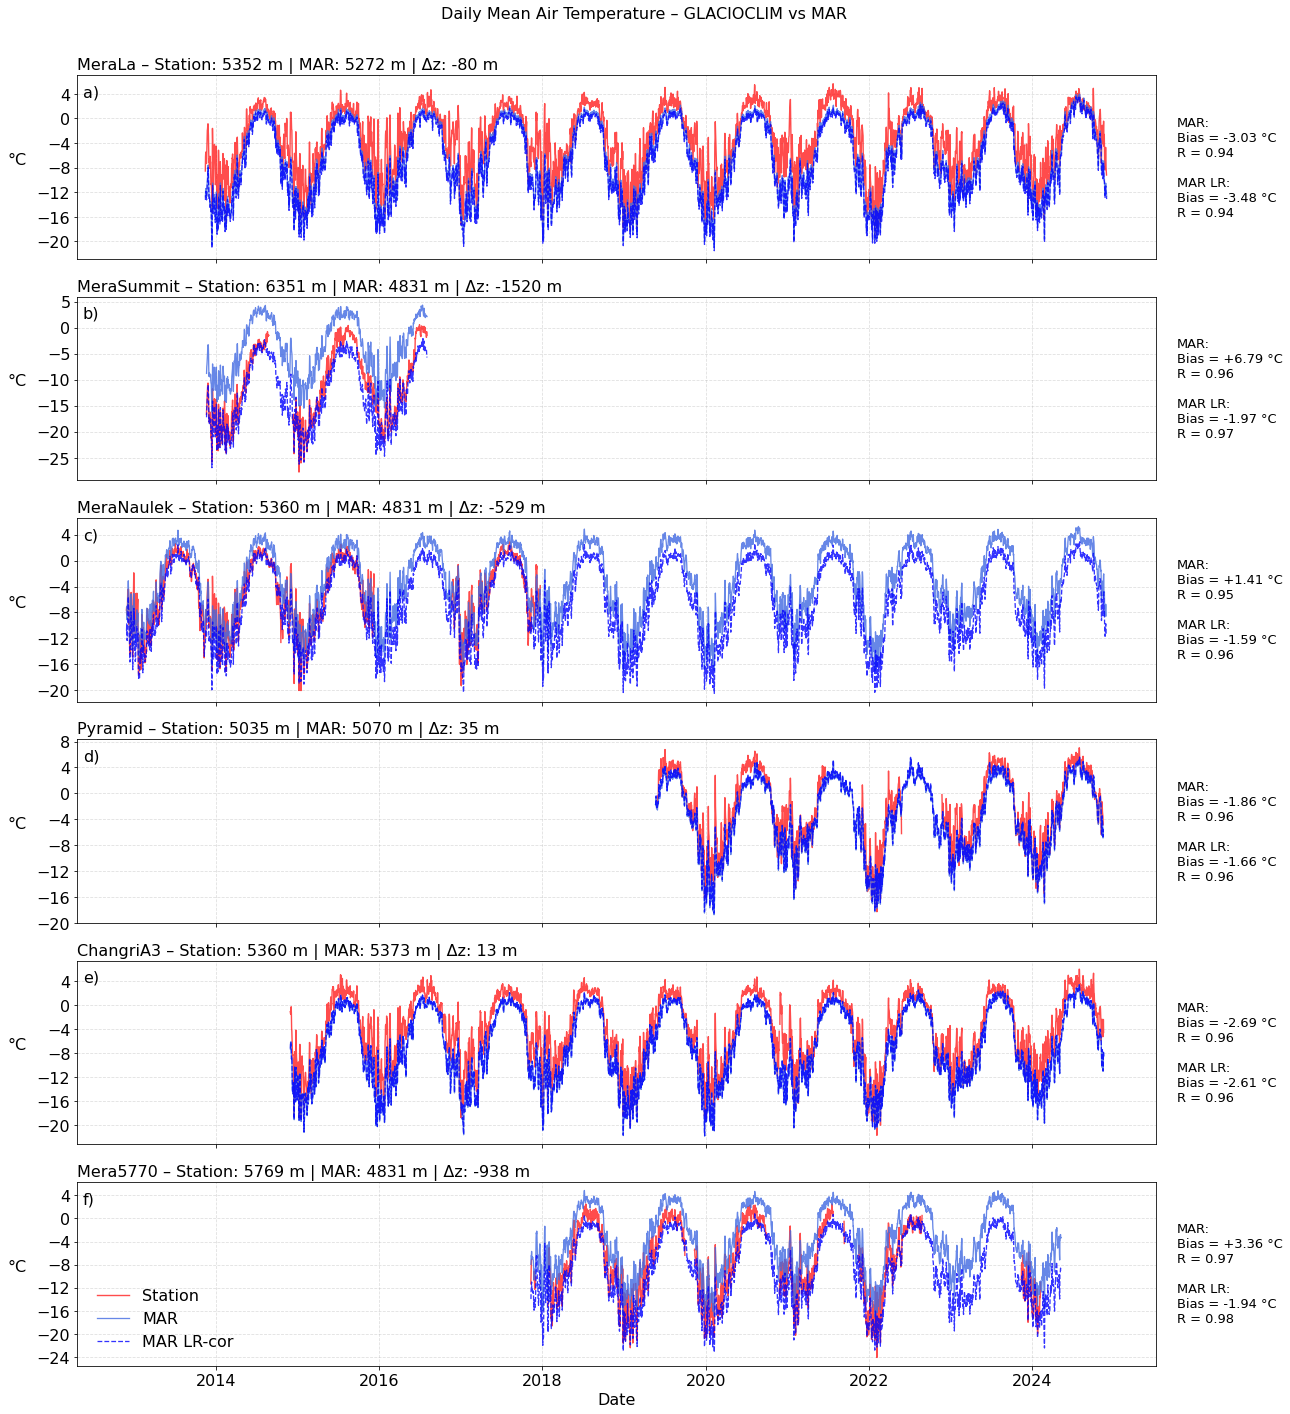

In [102]:
import matplotlib.pyplot as plt
import string
import matplotlib.ticker as mticker


# --- Observed daily mean temperature series ---
stations_tt_daily_glacioclim = {
    "MeraLa": tt_daily_ML,
    "MeraSummit": tt_daily_MS,
     "MeraNaulek": tt_daily_MN,
    "Pyramid": tt_daily_PYG,
    "ChangriA3": tt_daily_CHA3,
    "Mera5770": tt_daily_M57
}

# --- Model TTZ (temperature) at corresponding locations ---
ts_TTZ_model_glacioclim = {
    "MeraLa": ts_TTZ_ML,
    "MeraSummit": ts_TTZ_MS,
     "MeraNaulek": ts_TTZ_MN,
    "Pyramid": ts_TTZ_PYG,
    "ChangriA3": ts_TTZ_CHA3,
    "Mera5770": ts_TTZ_M57
}

ts_TTZ_model_lr_glacioclim = {
    "MeraLa": ts_TTZ_ML_lr,
    "MeraSummit": ts_TTZ_MS_lr,
     "MeraNaulek": ts_TTZ_MN_lr,
    "Pyramid": ts_TTZ_PYG_lr,
    "ChangriA3": ts_TTZ_CHA3_lr,
    "Mera5770":  ts_TTZ_M57_lr

}

# --- Station elevations (from metadata or logs) ---
elev_station_glacioclim = {
    "MeraLa": elev_ML,     # m
    "MeraSummit": elev_MS, # m
    "MeraNaulek": elev_MN,
    "Pyramid": elev_PYG,
    "ChangriA3": elev_CHA3,
    "Mera5770": elev_M57

}

# --- Model elevations (from surface height field) ---
elev_model_glacioclim = {
    "MeraLa": float(dsSH[jML, iML]),
    "MeraSummit": float(dsSH[jMS, iMS]),
    "MeraNaulek":  float(dsSH[jMN,iMN]),
    "Pyramid":  float(dsSH[jPYG,iPYG]),
    "ChangriA3":  float(dsSH[jCHA3,iCHA3]),
    "Mera5770":  float(dsSH[jM57,iM57])
}
labels=['a)','b)','c)','d)','e)','f)','g)']

# --- Create subplots (one per station) ---
fig, axes = plt.subplots(len(stations_tt_daily_glacioclim), 1, figsize=(18, 20), sharex=True)

# --- Plot each station ---
#for ax, (name, obs_series) in zip(axes, stations_tt_daily_glacioclim.items()):
for i, (ax, (name, obs_series)) in enumerate(zip(axes, stations_tt_daily_glacioclim.items())):
# Observed daily temperature (line)
    ax.plot(obs_series.time.values, obs_series.values, color='red', lw=1.4, alpha=0.7, label="Station")

    # Model daily temperature (line)
    model_series = ts_TTZ_model_glacioclim[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.3, alpha=0.8, label="MAR")

    model_series_lr = ts_TTZ_model_lr_glacioclim[name].to_pandas()
    ax.plot(model_series_lr.index, model_series_lr, color='blue',linestyle='dashed', lw=1.3,alpha=0.8, label="MAR LR-cor")

    # Elevations
    st_elev = elev_station_glacioclim[name]
    mod_elev = elev_model_glacioclim[name]
    diff_elev = mod_elev - st_elev

    # Style + Title
    ax.set_ylabel("°C", fontsize=16,rotation=0, labelpad=20)
    
    ax.set_title(f"{name} – Station: {st_elev:.0f} m | MAR: {mod_elev:.0f} m | Δz: {diff_elev:.0f} m",
                 loc='left', fontsize=16)#, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    #ax.legend(frameon=False, loc='upper right', fontsize=9)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=8))
    ax.tick_params(axis='y', labelsize=16)
    ax.text(0.005, 0.95, f"{string.ascii_lowercase[i]})",
    transform=ax.transAxes,
    fontsize=16,# fontweight='bold',
    va='top', ha='left'
     )
    s = stats_glacioclim[name]

    text_stats = (
    f"MAR:\n"
    f"Bias = {s['orig']['Bias']:+.2f} °C\n"
    f"R = {s['orig']['R']:.2f}\n\n"
    f"MAR LR:\n"
    f"Bias = {s['lr']['Bias']:+.2f} °C\n"
    f"R = {s['lr']['R']:.2f}"
)

    ax.text(
    1.02, 0.5, text_stats,
    transform=ax.transAxes,
    fontsize=13,
    va='center',
    ha='left'
)
handles, labels = axes[0].get_legend_handles_labels()

axes[-1].legend(
    handles, labels,
    loc='lower left',              # or 'upper right'
    bbox_to_anchor=(0.005, 0.01),   # fine control of position
    frameon=False,
    fontsize=16,                   # BIGGER legend text
    ncol=1
)
# Shared labels and figure title
axes[-1].set_xlabel("Date",fontsize=16)
axes[-1].tick_params(axis='x', labelsize=16)
fig.suptitle("Daily Mean Air Temperature – GLACIOCLIM vs MAR",fontsize=16)#, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_tas.glacioclim_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


In [ ]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{sta}−z_{model})$$')
## --- Lapse-rate correction for Salerno AWS stations ---

# --- AWS0 ---
elev_model_AWS0 = float(dsSH[jAWS0, iAWS0])
dz_AWS0 = (elev_AWS0-elev_model_AWS0) / 1000
ts_TTZ_AWS0_lr = ts_TTZ_AWS0 + lr_daily * dz_AWS0

# --- AWS1 ---
elev_model_AWS1 = float(dsSH[jAWS1, iAWS1])
dz_AWS1 = (elev_AWS1-elev_model_AWS1) / 1000
ts_TTZ_AWS1_lr = ts_TTZ_AWS1 + lr_daily * dz_AWS1

# --- AWS2 ---
elev_model_AWS2 = float(dsSH[jAWS2, iAWS2])
dz_AWS2 = (elev_AWS2-elev_model_AWS2) / 1000
ts_TTZ_AWS2_lr = ts_TTZ_AWS2 + lr_daily * dz_AWS2

# --- AWS3 ---
elev_model_AWS3 = float(dsSH[jAWS3, iAWS3])
dz_AWS3 = (elev_AWS3-elev_model_AWS3 ) / 1000
ts_TTZ_AWS3_lr = ts_TTZ_AWS3 + lr_daily * dz_AWS3

# --- AWS4 ---
elev_model_AWS4 = float(dsSH[jAWS4, iAWS4])
dz_AWS4 = (elev_AWS4-elev_model_AWS4 ) / 1000
ts_TTZ_AWS4_lr = ts_TTZ_AWS4 + lr_daily * dz_AWS4

# --- AWS5 ---
elev_model_AWS5 = float(dsSH[jAWS5, iAWS5])
dz_AWS5 = (elev_AWS5-elev_model_AWS5) / 1000
ts_TTZ_AWS5_lr = ts_TTZ_AWS5 + lr_daily * dz_AWS5


In [99]:
stats_salerno = {
    "AWS0": {
        "orig": {"Bias": -2.67, "R": 0.95},
        "lr":   {"Bias": -2.47, "R": 0.95},
    },
    "AWS1": {
        "orig": {"Bias": -2.41, "R": 0.95},
        "lr":   {"Bias": -2.21, "R": 0.95},
    },
    "AWS2": {
        "orig": {"Bias": -2.42, "R": 0.96},
        "lr":   {"Bias":  0.18, "R": 0.96},
    },
    "AWS3": {
        "orig": {"Bias": -2.19, "R": 0.90},
        "lr":   {"Bias":  1.02, "R": 0.91},
    },
    "AWS4": {
        "orig": {"Bias": -2.15, "R": 0.95},
        "lr":   {"Bias": -2.83, "R": 0.95},
    },
    "AWS5": {
        "orig": {"Bias": -2.94, "R": 0.95},
        "lr":   {"Bias":  0.20, "R": 0.95},
    },
}


 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_tas.salerno_MAR.GRc.png


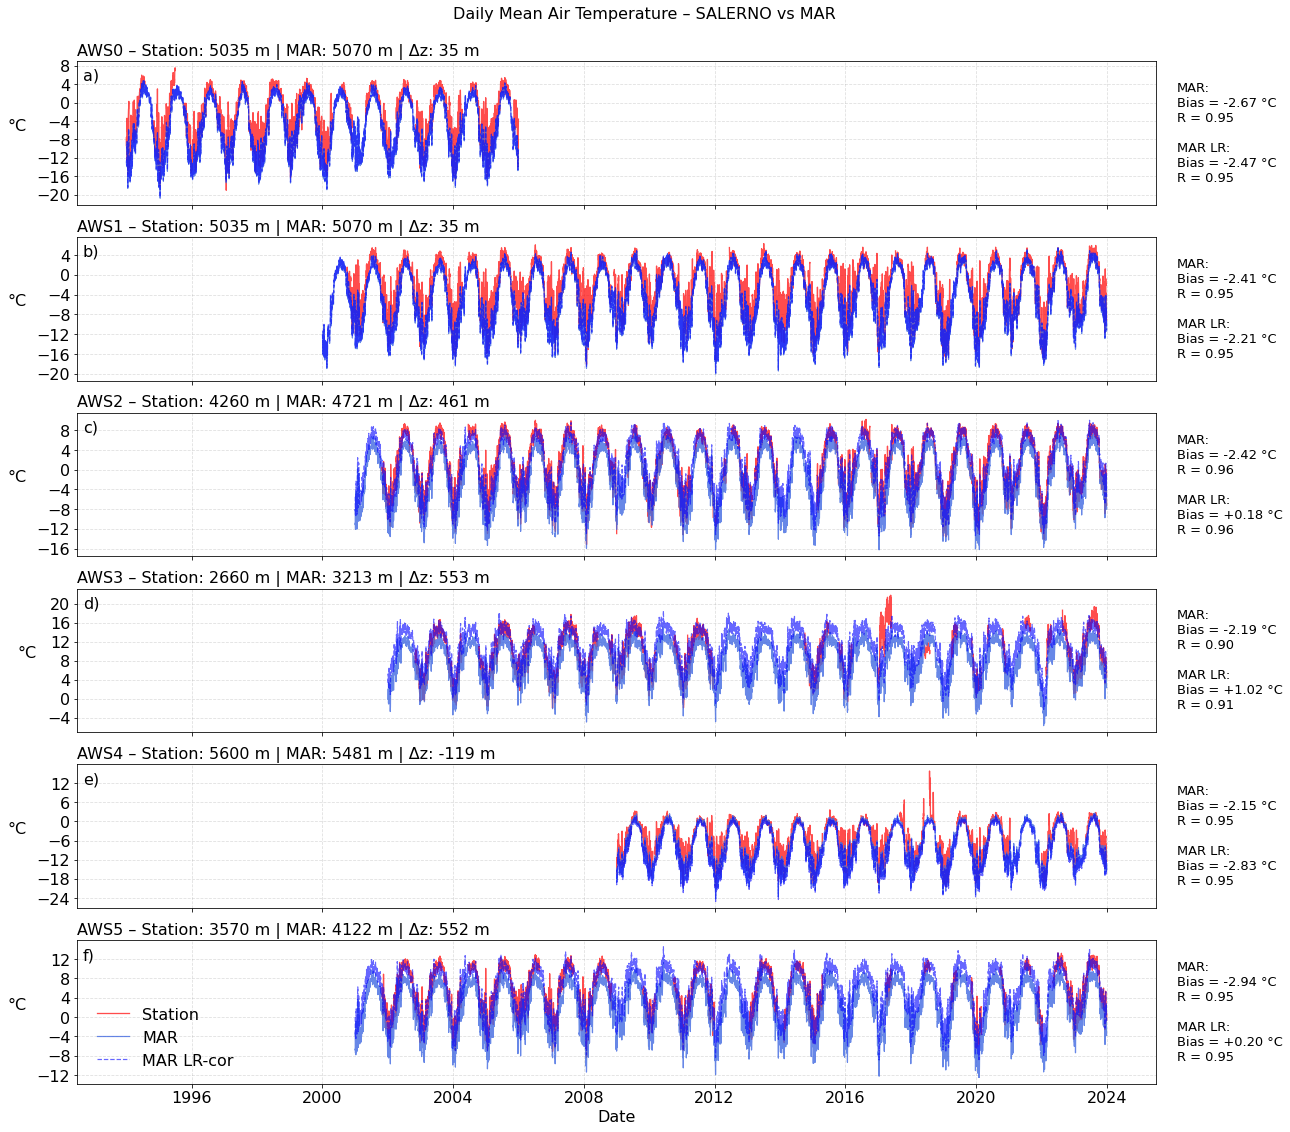

In [100]:

# --- Observed daily mean temperature (°C) ---
stations_tt_daily_salerno = {
    "AWS0": tt_AWS0_daily,
    "AWS1": tt_AWS1_daily,
    "AWS2": tt_AWS2_daily,
    "AWS3": tt_AWS3_daily,
    "AWS4": tt_AWS4_daily,
    "AWS5": tt_AWS5_daily,
}

# --- Model TTZ (temperature) for each AWS station ---
ts_TTZ_model_salerno = {
    "AWS0": ts_TTZ_AWS0,
    "AWS1": ts_TTZ_AWS1,
    "AWS2": ts_TTZ_AWS2,
    "AWS3": ts_TTZ_AWS3,
    "AWS4": ts_TTZ_AWS4,
    "AWS5": ts_TTZ_AWS5,
}

ts_TTZ_model_salerno_lr = {
    "AWS0": ts_TTZ_AWS0_lr,
    "AWS1": ts_TTZ_AWS1_lr,
    "AWS2": ts_TTZ_AWS2_lr,
    "AWS3": ts_TTZ_AWS3_lr,
    "AWS4": ts_TTZ_AWS4_lr,
    "AWS5": ts_TTZ_AWS5_lr,
}

# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

# --- Model grid elevation (from surface height field) ---
elev_model_salerno = {
    "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
}


fig, axes = plt.subplots(len(stations_tt_daily_salerno), 1, figsize=(18, 16), sharex=True)

for i, (ax, (name, obs_series)) in enumerate(zip(axes, stations_tt_daily_salerno.items())):
#for ax, (name, obs_series) in zip(axes, stations_tt_daily_salerno.items()):
    # Observed daily mean temperature 
    ax.plot(obs_series.index, obs_series, color='red', lw=1.3, alpha=0.7, label="Station")

    # Model TTZ temperature 
    model_series = ts_TTZ_model_salerno[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.2, alpha=0.8, label="MAR")
   
    # Model TTZ temperature lapse rate
    model_series_lr = ts_TTZ_model_salerno_lr[name].to_pandas()
    ax.plot(model_series_lr.index, model_series_lr, color='blue', linestyle='dashed',lw=1.2, alpha=0.6, label="MAR LR-cor")

    # Elevations
    st_elev = elev_station_salerno[name]
    mod_elev = elev_model_salerno[name]
    diff_elev = mod_elev - st_elev

    # Style + Title
    ax.set_ylabel("°C", fontsize=16,rotation=0, labelpad=20)
    
    ax.set_title(f"{name} – Station: {st_elev:.0f} m | MAR: {mod_elev:.0f} m | Δz: {diff_elev:.0f} m",
                 loc='left', fontsize=16)#, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    #ax.legend(frameon=False, loc='upper right', fontsize=9)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=8))
    ax.tick_params(axis='y', labelsize=16)
    ax.text(0.005, 0.95, f"{string.ascii_lowercase[i]})",
    transform=ax.transAxes,
    fontsize=16,# fontweight='bold',
    va='top', ha='left'
     )
    s = stats_salerno[name]

    text_stats = (
    f"MAR:\n"
    f"Bias = {s['orig']['Bias']:+.2f} °C\n"
    f"R = {s['orig']['R']:.2f}\n\n"
    f"MAR LR:\n"
    f"Bias = {s['lr']['Bias']:+.2f} °C\n"
    f"R = {s['lr']['R']:.2f}"
)

    ax.text(
    1.02, 0.5, text_stats,
    transform=ax.transAxes,
    fontsize=13,
    va='center',
    ha='left'
)
handles, labels = axes[0].get_legend_handles_labels()

axes[-1].legend(
    handles, labels,
    loc='lower left',              # or 'upper right'
    bbox_to_anchor=(0.005, 0.01),   # fine control of position
    frameon=False,
    fontsize=16,                   # BIGGER legend text
    ncol=1
)

axes[-1].set_xlabel("Date",fontsize=16)
axes[-1].tick_params(axis='x', labelsize=16)
fig.suptitle("Daily Mean Air Temperature – SALERNO vs MAR",fontsize=16)#, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_tas.salerno_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


In [54]:
print('$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{station}−z_{model})$$')
## --- Lapse-rate correction for Salerno AWS stations ---

# --- Base Camp ---
elev_model_bc = float(dsSH[jbc, ibc])
dz_bc = (elev_bc - elev_model_bc) / 1000
ts_TTZ_bc_lr = ts_TTZ_bc + lr_daily * dz_bc

# --- Camp 2 ---
elev_model_c2 = float(dsSH[jc2, ic2])
dz_c2 = (elev_c2 - elev_model_c2) / 1000
ts_TTZ_c2_lr = ts_TTZ_c2 + lr_daily * dz_c2

# --- Phortse ---
elev_model_phort = float(dsSH[jphort, iphort])
dz_phort = (elev_phort - elev_model_phort) / 1000
ts_TTZ_phort_lr = ts_TTZ_phort + lr_daily * dz_phort

# --- Bishop Rock ---
elev_model_bish = float(dsSH[jbish, ibish])
dz_bish = (elev_bish - elev_model_bish) / 1000
ts_TTZ_bish_lr = ts_TTZ_bish + lr_daily * dz_bish

# --- South Col ---
elev_model_sc = float(dsSH[jsc, isc])
dz_sc = (elev_sc - elev_model_sc) / 1000
ts_TTZ_sc_lr = ts_TTZ_sc + lr_daily * dz_sc


$$T_{corr}(t)=T_{MAR}(t)+\Gamma(t)×\Delta(z_{station}−z_{model})$$


In [97]:
stats_natgeo = {
    "BaseCamp": {
        "orig": {"Bias": -4.25, "R": 0.95},
        "lr":   {"Bias": -3.32, "R": 0.95},
    },
    "Camp2": {
        "orig": {"Bias":  2.84, "R": 0.96},
        "lr":   {"Bias": -2.14, "R": 0.96},
    },
    "Phortse": {
        "orig": {"Bias": -0.97, "R": 0.96},
        "lr":   {"Bias":  0.51, "R": 0.96},
    },
    "BishopRock": {
        "orig": {"Bias": 19.01, "R": 0.90},
        "lr":   {"Bias":  1.66, "R": 0.91},
    },
    "SouthCol": {
        "orig": {"Bias": 14.06, "R": 0.97},
        "lr":   {"Bias":  1.02, "R": 0.96},
    },
}


 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_tas.natgeo_MAR.GRc.png


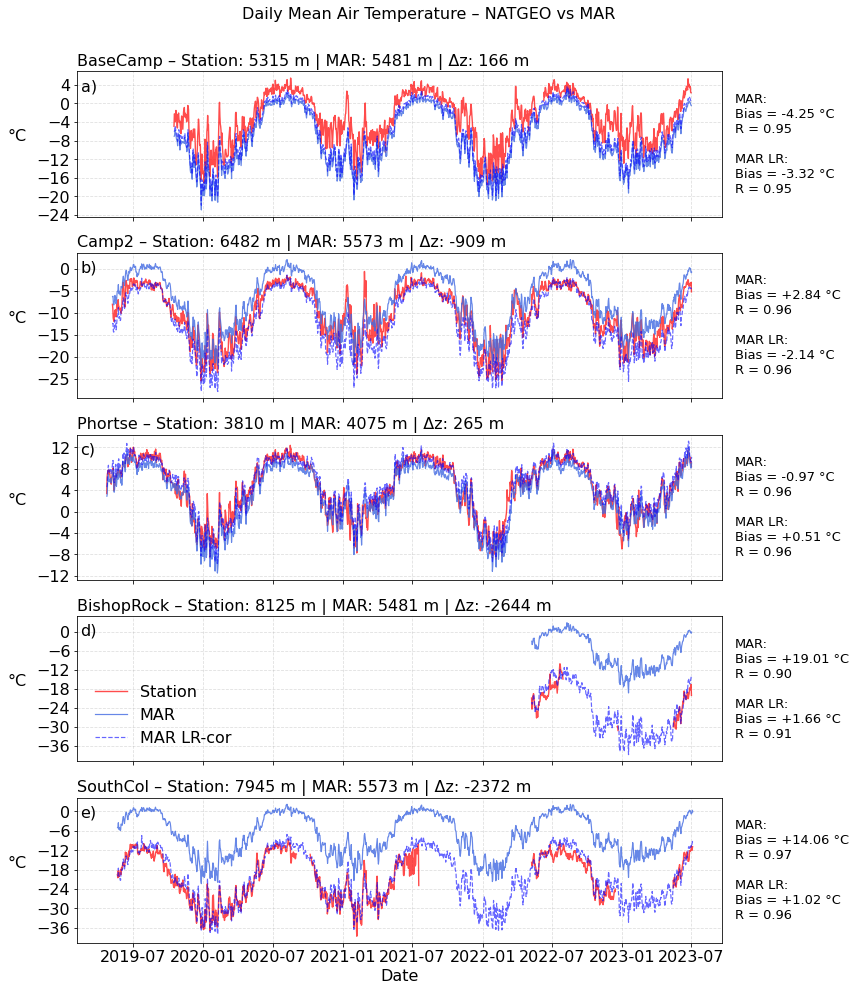

In [98]:
# --- Observed daily mean temperature (°C) ---
stations_tt_daily_natgeo = {
    "BaseCamp": tt_bc_daily,
    "Camp2": tt_c2_daily,
    "Phortse": tt_phort_daily,
    "BishopRock": tt_bish_daily,
    "SouthCol": tt_sc_daily,
}

# --- Model TTZ time series ---
ts_TTZ_model_natgeo = {
    "BaseCamp": ts_TTZ_bc,
    "Camp2": ts_TTZ_c2,
    "Phortse": ts_TTZ_phort,
    "BishopRock": ts_TTZ_bish,
    "SouthCol": ts_TTZ_sc,
}

ts_TTZ_model_natgeo_lr = {
    "BaseCamp": ts_TTZ_bc_lr,
    "Camp2": ts_TTZ_c2_lr,
    "Phortse": ts_TTZ_phort_lr,
    "BishopRock": ts_TTZ_bish_lr,
    "SouthCol": ts_TTZ_sc_lr,
}


# --- Station elevations (m) ---
elev_station_natgeo = {
    "BaseCamp": 5315,
    "Camp2": 6482,
    "Phortse": 3810,
    "BishopRock": 8125,
    "SouthCol": 7945,
}

# --- Model grid elevations (from dsSH) ---
elev_model_natgeo = {
    "BaseCamp": float(dsSH[jbc, ibc]),
    "Camp2": float(dsSH[jc2, ic2]),
    "Phortse": float(dsSH[jphort, iphort]),
    "BishopRock": float(dsSH[jbish, ibish]),
    "SouthCol": float(dsSH[jsc, isc]),
}

# --- Create subplots ---
fig, axes = plt.subplots(len(stations_tt_daily_natgeo), 1, figsize=(12, 14), sharex=True)

# --- Loop over stations ---
for i, (ax, (name, obs_series)) in enumerate(zip(axes, stations_tt_daily_natgeo.items())):
    # Observed temperature (line)
    ax.plot(obs_series.index, obs_series, color='red', lw=1.4, alpha=0.7, label="Station")

    # Model TTZ (line)
    model_series = ts_TTZ_model_natgeo[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.2, alpha=0.8, label="MAR")
   # Model TTZ  LR (line)
    model_series_lr = ts_TTZ_model_natgeo_lr[name].to_pandas()
    ax.plot(model_series_lr.index, model_series_lr, color='blue',linestyle='dashed', lw=1.2, alpha=0.6, label="MAR LR-cor")

    # Elevation info
    st_elev = elev_station_natgeo[name]
    mod_elev = elev_model_natgeo[name]
    diff_elev = mod_elev - st_elev

     # Style + Title
    ax.set_ylabel("°C", fontsize=16,rotation=0, labelpad=20)
    
    ax.set_title(f"{name} – Station: {st_elev:.0f} m | MAR: {mod_elev:.0f} m | Δz: {diff_elev:.0f} m",
                 loc='left', fontsize=16)#, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    #ax.legend(frameon=False, loc='upper right', fontsize=9)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=8))
    ax.tick_params(axis='y', labelsize=16)
    ax.text(0.005, 0.95, f"{string.ascii_lowercase[i]})",
    transform=ax.transAxes,
    fontsize=16,# fontweight='bold',
    va='top', ha='left'
     )
    s = stats_natgeo[name]

    text_stats = (
    f"MAR:\n"
    f"Bias = {s['orig']['Bias']:+.2f} °C\n"
    f"R = {s['orig']['R']:.2f}\n\n"
    f"MAR LR:\n"
    f"Bias = {s['lr']['Bias']:+.2f} °C\n"
    f"R = {s['lr']['R']:.2f}"
)

    ax.text(
    1.02, 0.5, text_stats,
    transform=ax.transAxes,
    fontsize=13,
    va='center',
    ha='left'
) 

handles, labels = axes[0].get_legend_handles_labels()

axes[-2].legend(
    handles, labels,
    loc='lower left',              # or 'upper right'
    bbox_to_anchor=(0.005, 0.01),   # fine control of position
    frameon=False,
    fontsize=16,                   # BIGGER legend text
    ncol=1
)

axes[-1].set_xlabel("Date",fontsize=16)
axes[-1].tick_params(axis='x', labelsize=16)
fig.suptitle("Daily Mean Air Temperature – NATGEO vs MAR",fontsize=16)#, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_tas.natgeo_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()

